<a href="https://colab.research.google.com/github/RohanSNikam/Logistics-Delivery-Time-Analysis/blob/main/notebooks/logistics_delivery_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Logistics Delivery Time Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Project started successfully!")
print("Ready to explore logistics delivery data.")

Project started successfully!
Ready to explore logistics delivery data.


In [2]:
from google.colab import files

uploaded = files.upload()

Saving logistics_delivery_data.csv to logistics_delivery_data.csv


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv("logistics_delivery_data.csv")

print("Dataset loaded successfully!")
print(data.head())


Dataset loaded successfully!
  order_id  order_date  distance_km traffic_level weather vehicle_type  \
0  ORD0001  2026-01-17           61        Medium   Clear          Van   
1  ORD0002  2026-05-20          328          High   Clear        Truck   
2  ORD0003  2026-04-28          482          High   Clear          Van   
3  ORD0004  2026-03-20          435        Medium   Clear          Van   
4  ORD0005  2026-03-19          140        Medium   Clear        Truck   

   order_value_inr  promised_delivery_minutes  actual_delivery_minutes  \
0             4899                        115                       95   
1            12673                        372                      401   
2              722                        676                      689   
3             6807                        617                      607   
4            12055                        180                      186   

   delivery_cost_inr delivery_status  
0             137.09         On Time  
1  

In [4]:

# 1. Check the number of rows and columns
print("Dataset shape:", data.shape)

# 2. Display all column names
print("\nColumn names:")
print(data.columns.tolist())

# 3. Check data types and missing values
print("\nDataset information:")
data.info()

# 4. Count missing values in each column
print("\nMissing values:")
print(data.isnull().sum())


Dataset shape: (500, 11)

Column names:
['order_id', 'order_date', 'distance_km', 'traffic_level', 'weather', 'vehicle_type', 'order_value_inr', 'promised_delivery_minutes', 'actual_delivery_minutes', 'delivery_cost_inr', 'delivery_status']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   order_id                   500 non-null    object 
 1   order_date                 500 non-null    object 
 2   distance_km                500 non-null    int64  
 3   traffic_level              492 non-null    object 
 4   weather                    495 non-null    object 
 5   vehicle_type               500 non-null    object 
 6   order_value_inr            500 non-null    int64  
 7   promised_delivery_minutes  500 non-null    int64  
 8   actual_delivery_minutes    500 non-null    int64  
 9   delivery_co

In [5]:

# Step 4: Check duplicate records
print("Duplicate rows:", data.duplicated().sum())

# Check duplicate order IDs
print("Duplicate order IDs:", data["order_id"].duplicated().sum())

# Check missing values
print("\nMissing values before cleaning:")
print(data.isnull().sum())


Duplicate rows: 0
Duplicate order IDs: 0

Missing values before cleaning:
order_id                     0
order_date                   0
distance_km                  0
traffic_level                8
weather                      5
vehicle_type                 0
order_value_inr              0
promised_delivery_minutes    0
actual_delivery_minutes      0
delivery_cost_inr            4
delivery_status              0
dtype: int64


In [6]:

# Step 5: Create a cleaned copy of the dataset
cleaned_data = data.copy()

# Fill missing categorical values
cleaned_data["traffic_level"] = (
    cleaned_data["traffic_level"].fillna("Unknown")
)

cleaned_data["weather"] = (
    cleaned_data["weather"].fillna("Unknown")
)

# Fill missing delivery costs using the median
median_cost = cleaned_data["delivery_cost_inr"].median()

cleaned_data["delivery_cost_inr"] = (
    cleaned_data["delivery_cost_inr"].fillna(median_cost)
)

# Check missing values after cleaning
print("Missing values after cleaning:")
print(cleaned_data.isnull().sum())

print("\nDataset shape after cleaning:", cleaned_data.shape)
print("\nMedian delivery cost used:", median_cost)


Missing values after cleaning:
order_id                     0
order_date                   0
distance_km                  0
traffic_level                0
weather                      0
vehicle_type                 0
order_value_inr              0
promised_delivery_minutes    0
actual_delivery_minutes      0
delivery_cost_inr            0
delivery_status              0
dtype: int64

Dataset shape after cleaning: (500, 11)

Median delivery cost used: 465.21000000000004


In [7]:

# Step 6: Calculate logistics KPIs

# Calculate delivery delay in minutes
cleaned_data["delay_minutes"] = (
    cleaned_data["actual_delivery_minutes"]
    - cleaned_data["promised_delivery_minutes"]
)

# KPI 1: Average actual delivery time
average_delivery_time = cleaned_data["actual_delivery_minutes"].mean()

# KPI 2: Average delivery delay
average_delay = cleaned_data["delay_minutes"].mean()

# KPI 3: On-time delivery rate
on_time_orders = (
    cleaned_data["actual_delivery_minutes"]
    <= cleaned_data["promised_delivery_minutes"]
).sum()

total_orders = len(cleaned_data)

on_time_rate = (on_time_orders / total_orders) * 100

# Display results
print("Total orders:", total_orders)
print("Average delivery time:", round(average_delivery_time, 2), "minutes")
print("Average delivery delay:", round(average_delay, 2), "minutes")
print("On-time delivery rate:", round(on_time_rate, 2), "%")


Total orders: 500
Average delivery time: 422.44 minutes
Average delivery delay: 2.45 minutes
On-time delivery rate: 47.0 %


delivery_status
Delayed    265
On Time    235
Name: count, dtype: int64


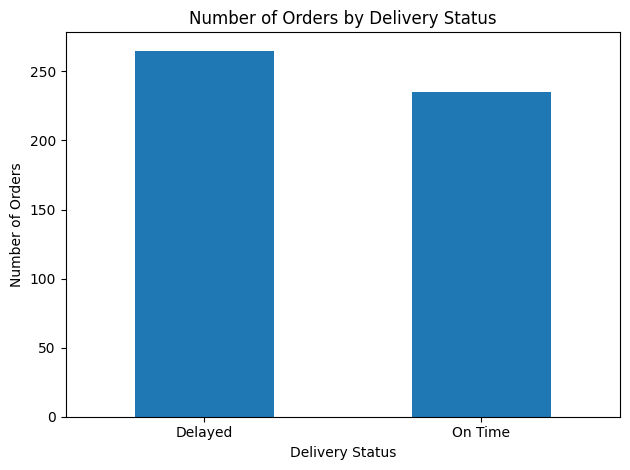

In [8]:

# Step 8: Count delivery status
status_counts = cleaned_data["delivery_status"].value_counts()

print(status_counts)

# Create a bar chart
status_counts.plot(kind="bar")

plt.title("Number of Orders by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [9]:

# Step 9: Analyze delays by traffic level

traffic_analysis = cleaned_data.groupby("traffic_level").agg(
    total_orders=("order_id", "count"),
    average_delay=("delay_minutes", "mean"),
    average_delivery_time=("actual_delivery_minutes", "mean")
).round(2)

print(traffic_analysis)


               total_orders  average_delay  average_delivery_time
traffic_level                                                    
High                    133          25.12                 465.82
Low                     155         -18.52                 410.09
Medium                  204           3.22                 408.52
Unknown                   8          12.62                 295.50


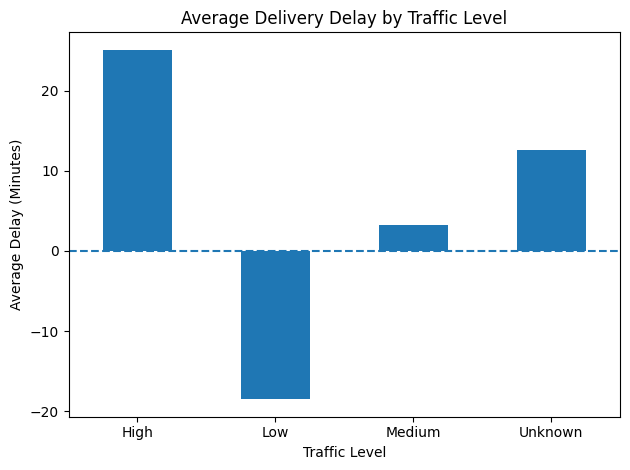

In [10]:

# Step 10: Plot average delivery delay by traffic level

traffic_analysis["average_delay"].plot(kind="bar")

plt.title("Average Delivery Delay by Traffic Level")
plt.xlabel("Traffic Level")
plt.ylabel("Average Delay (Minutes)")
plt.axhline(y=0, linestyle="--")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
